# Model 2: 5th-Degree Polynomial Regression

This notebook estimates a fifth-degree polynomial expansion across log-moneyness m and maturity T to capture the global curvature (volatility smile and skew term structure) of the S&P 500 implied volatility surface.

**Author:** Sérgio da Cunha Sobral
**Degree:** Master in Financial Mathematics (ISCTE-IUL)
**Supervisor:** Prof.ª Doutora Diana Mendes


### 1. Library Imports


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os, json, joblib
from datetime import datetime
from typing import Sequence, Optional
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import Pipeline

### 2. Core Paths & Configuration


In [2]:
# Core Paths and Configuration
DIR_TRATADOS = "02_data/processed/"
DIR_RESULTADOS = "04_outputs/03_models_metadata/02_model_polynomial/"
DIR_GRAFICOS = "04_outputs/01_figures/05_model_polynomial/"
DIR_TABELAS = "04_outputs/02_tables/02_model_polynomial/"

# Ensure output directories exist
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Input data splits
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Config
FEATURES = ("log_moneyness", "T")
TARGET = "iv_teorica"

# Model and metadata paths
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "02. Polinomial_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "02. Polinomial_model_inner.meta.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "02. Polinomial_model_final.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "02. Polinomial_model_final.meta.json")

### 3. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


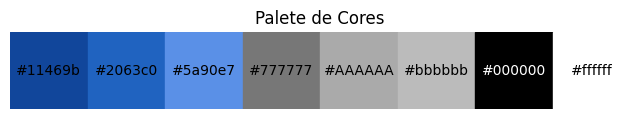

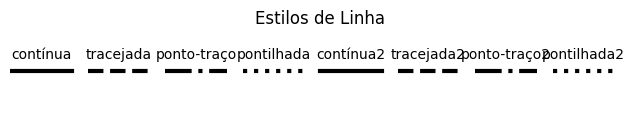

In [3]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

### 4. Data Ingestion (Train, Tuning, and Test Splits)


In [4]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

### 5. Modeling Setup & Pre-estimation Checks


In [5]:
# 1) Checks básicos 
def _basic_checks(df: pd.DataFrame, features, target):
    cols_necessarias = list(features) + [target]
    em_falta = [c for c in cols_necessarias if c not in df.columns]
    if em_falta:
        raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols_necessarias]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        detalhe = nan_counts[nan_counts > 0].to_dict()
        raise ValueError(f"Há NaN nas colunas usadas: {detalhe}")

    arr = sub.to_numpy(dtype=float)
    if not np.isfinite(arr).all():
        inf_detalhe = {}
        for c in cols_necessarias:
            v = df[c].to_numpy(dtype=float)
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub


# -----------------------------------
# 2) Construção do pipeline polinomial
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import Pipeline

def make_poly_pipeline(
    degree: int = 2,
    use_ridge: bool = True,
    alphas: Optional[Sequence[float]] = None,
    include_bias: bool = False,
    interaction_only: bool = False,
    with_scaler: bool = True,
    fit_intercept: bool = True,
) -> Pipeline:
    """
    Pipeline: PolynomialFeatures -> (StandardScaler) -> (RidgeCV | LinearRegression)
    """
    if degree < 1:
        raise ValueError("degree deve ser >= 1")

    if alphas is None:
        alphas = np.logspace(-6, 3, 10)

    steps = [
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=include_bias,      # intercepto tratado no regressor
            interaction_only=interaction_only
        )),
    ]
    if with_scaler:
        steps.append(("scaler", StandardScaler()))
    if use_ridge:
        steps.append(("reg", RidgeCV(alphas=alphas, fit_intercept=fit_intercept)))
    else:
        steps.append(("reg", LinearRegression(fit_intercept=fit_intercept)))
    return Pipeline(steps)

# -----------------------------------
# 3) Treino polinomial
def train_polynomial(
    df: pd.DataFrame,
    features=FEATURES,
    target=TARGET,
    degree: int = 2,
    use_ridge: bool = True,
    alphas: Optional[Sequence[float]] = None,
    interaction_only: bool = False,
    with_scaler: bool = True,
    pred_col: Optional[str] = None,
):
    """
    Treina um modelo polinomial (com RidgeCV opcional).
    Retorna (model_pipeline, meta, df_out_com_pred).
    """
    sub = _basic_checks(df, features, target)
    X = sub[list(features)].to_numpy(dtype=float)
    y = sub[target].to_numpy(dtype=float)

    pipe = make_poly_pipeline(
        degree=degree,
        use_ridge=use_ridge,
        alphas=alphas,
        include_bias=False,
        interaction_only=interaction_only,
        with_scaler=with_scaler,
        fit_intercept=True,
    )
    pipe.fit(X, y)

    # Infos do poly
    poly = pipe.named_steps["poly"]
    n_out_feats = poly.n_output_features_
    feat_names = None
    try:
        feat_names = list(poly.get_feature_names_out(input_features=list(features)))
    except Exception:
        # versões antigas de sklearn usam get_feature_names
        feat_names = list(poly.get_feature_names(input_features=list(features)))

    # Coeficientes do regressor final (atenção: referem-se às features pós-transformação)
    reg = pipe.named_steps["reg"]
    intercept = float(reg.intercept_)
    coefs = list(reg.coef_.ravel().tolist())  # alinhado com feat_names

    # Coluna de previsão
    if pred_col is None:
        pred_col = f"iv_poly_d{degree}"
        if use_ridge:
            pred_col += "_ridge"

    y_hat = pipe.predict(X)
    df_out = df.copy()
    df_out[pred_col] = y_hat

    # alpha* (se RidgeCV)
    alpha_star = getattr(reg, "alpha_", None)

    meta = {
        "model_type": "Polynomial Regression (Pipeline)",
        "base_regressor": "RidgeCV" if use_ridge else "LinearRegression",
        "degree": int(degree),
        "interaction_only": bool(interaction_only),
        "with_scaler": bool(with_scaler),
        "features_original": list(features),
        "features_expanded_count": int(n_out_feats),
        "features_expanded_names": feat_names,
        "target": target,
        "fit_intercept": True,
        "n_obs": int(X.shape[0]),
        "intercept": intercept,
        # Nota: coeficientes relativos às features EXPANDIDAS (após poly [+ scaler])
        "coefs_expanded": {name: float(c) for name, c in zip(feat_names, coefs)},
        "alpha_star": float(alpha_star) if alpha_star is not None else None,
        "trained_at": datetime.utcnow().isoformat() + "Z",
        "date_min": str(df['quote_date'].min()) if 'quote_date' in df.columns else None,
        "date_max": str(df['quote_date'].max()) if 'quote_date' in df.columns else None,
        "pred_col": pred_col,
    }
    return pipe, meta, df_out

# -----------------------------------
# 4) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

# -----------------------------------
# 5) Aplicar modelo
def apply_model(df: pd.DataFrame, model, features=FEATURES, pred_col="ivs_modelo"):
    """
    Aplica QUALQUER modelo sklearn/pipeline com .predict
    """
    cols = list(features)
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta:
        raise ValueError(f"Colunas em falta para aplicar o modelo: {em_falta}")

    X = df[cols].to_numpy(dtype=float)
    if not np.isfinite(X).all():
        raise ValueError("Valores não finitos nos FEATURES ao aplicar o modelo.")

    y_hat = model.predict(X)
    df_out = df.copy()
    df_out[pred_col] = y_hat
    return df_out

### 6. In-Sample Training (inner_train)


In [6]:
# Hiperparâmetros de base para este treino
DEGREE    = 4          # ajusta no tuning (p.ex. 2, 3, 4)
USE_RIDGE = True       # recomendável para estabilidade
ALPHAS    = None       # usa defaults (logspace); ou define np.logspace(-6, 3, 10)

model_inner, meta_inner, df_inner_train_pred = train_polynomial(
    df_inner_train,
    features=FEATURES,
    target=TARGET,
    degree=DEGREE,
    use_ridge=USE_RIDGE,
    alphas=ALPHAS,
    interaction_only=False,
    with_scaler=True,
    pred_col="ivs_modelo"   # normaliza nome para avaliação
)

# Save figures modelo/metadata do treino inner usando DIR_RESULTADOS
save_model(model_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

# ── Impressão resumida
print("=== POLINOMIAL | Treino (inner_train) ===")
print(f"- Grau (degree): {meta_inner['degree']}")
print(f"- Base regressor: {meta_inner['base_regressor']}")
print(f"- Observações: {meta_inner['n_obs']}")
print(f"- Features originais: {len(meta_inner['features_original'])} -> expandidas: {meta_inner['features_expanded_count']}")
print(f"- Intercepto: {meta_inner['intercept']:.8f}")
if meta_inner.get("alpha_star") is not None:
    print(f"- alpha* (RidgeCV): {meta_inner['alpha_star']:.6g}")
print(f"- Coluna de previsão criada: {meta_inner['pred_col']}")
print(f"- Modelo guardado em: {MODEL_PATH_INNER}")
print(f"- Metadados guardados em: {META_PATH_INNER}")
print("=========================================")

# Mostrar os 10 termos com |coef| maior (no espaço expandido)
coefs_exp = meta_inner["coefs_expanded"]
top = sorted(coefs_exp.items(), key=lambda kv: abs(kv[1]), reverse=True)[:10]
print("\nTop 10 termos (|coef|):")
for name, val in top:
    print(f"  • {name:<20s} {val:+.6f}")

=== POLINOMIAL | Treino (inner_train) ===
- Grau (degree): 4
- Base regressor: RidgeCV
- Observações: 5970843
- Features originais: 2 -> expandidas: 14
- Intercepto: 0.22031264
- alpha* (RidgeCV): 0.1
- Coluna de previsão criada: ivs_modelo
- Modelo guardado em: 04. Resultados/02. Modelo #2 - Polinomial/02. Polinomial_model_inner.joblib
- Metadados guardados em: 04. Resultados/02. Modelo #2 - Polinomial/02. Polinomial_model_inner.meta.json

Top 10 termos (|coef|):
  • T^3                  -0.764038
  • log_moneyness T^2    -0.701231
  • T^2                  +0.575512
  • log_moneyness T      +0.426485
  • log_moneyness^2 T    -0.379088
  • log_moneyness T^3    +0.361037
  • log_moneyness^2      +0.348510
  • T^4                  +0.338527
  • log_moneyness^3      +0.232016
  • log_moneyness^2 T^2  +0.152098


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


### 7. Hyperparameter Tuning & Validation (inner_tunning)


In [7]:
# Modelo #2 — Regressão Polinomial | Tuning no inner_tunning

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

DEGREES    = [1, 2, 3, 4, 5, 6, 7, 8]   # 1 = OLS no espaço original; >=2 já com termos não lineares
USE_RIDGE  = True           # recomendado para estabilidade
ALPHAS     = None           # usa defaults (np.logspace(-6, 3, 10))

results = []

print("=== POLINOMIAL | Tuning (inner_tunning) ===")
for d in DEGREES:
    # 1) treinar no inner_train com grau d
    model_d, meta_d, df_inner_train_pred_d = train_polynomial(
        df_inner_train,
        features=FEATURES,
        target=TARGET,
        degree=d,
        use_ridge=USE_RIDGE,
        alphas=ALPHAS,
        interaction_only=False,
        with_scaler=True,
        pred_col="ivs_modelo"   # normaliza nome
    )

    # 2) aplicar em inner_tunning
    df_inner_tunning_pred_d = apply_model(
        df_inner_tunning, model_d, features=FEATURES, pred_col="ivs_modelo"
    )

    # 3) métricas em inner_tunning
    y_true = df_inner_tunning_pred_d[TARGET].to_numpy(dtype=float)
    y_pred = df_inner_tunning_pred_d["ivs_modelo"].to_numpy(dtype=float)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    mae    = mean_absolute_error(y_true, y_pred)
    r2     = r2_score(y_true, y_pred)
    bias   = float(np.mean(y_pred - y_true))

    results.append({
        "degree": d,
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "bias": bias,
        "alpha_star": meta_d.get("alpha_star"),
        "features_expanded": meta_d["features_expanded_count"],
        "model": model_d,
        "meta": meta_d,
        "pred_col": "ivs_modelo",
        # guarda também o df com preds do tunning, útil para não recomputar se ganhar
        "df_inner_tunning_pred": df_inner_tunning_pred_d
    })

    alpha_txt = f"{meta_d.get('alpha_star'):.6g}" if meta_d.get("alpha_star") is not None else "—"
    print(f"- d={d:<2d} | RMSE={rmse:.6f} | MAE={mae:.6f} | R²={r2:.4f} | bias={bias:+.6f} | α*={alpha_txt} | feats={meta_d['features_expanded_count']}")

# 4) escolher melhor grau (RMSE mínimo + margem 0.5% e menor grau)
res_sorted = sorted(results, key=lambda r: r["rmse"])
rmse_min = res_sorted[0]["rmse"]
candidates = [r for r in res_sorted if (r["rmse"] - rmse_min)/rmse_min <= 0.005]  # 0.5%
best = min(candidates, key=lambda r: r["degree"])

best_degree = best["degree"]
model_inner_best = best["model"]
meta_inner_best  = best["meta"]
pred_col_best    = best["pred_col"]
df_inner_tunning_pred = best["df_inner_tunning_pred"]  # já com a coluna certa

print("------------------------------------------------")
print(f"> Grau escolhido: d={best_degree} (regra 0.5% + simplicidade)")
if meta_inner_best.get("alpha_star") is not None:
    print(f"> alpha* (RidgeCV): {meta_inner_best['alpha_star']:.6g}")
print(f"> Coluna de previsão: {pred_col_best}")
print("================================================")


# (Opcional) guardar tabela de resultados do tuning
import pandas as pd
tunning_table = pd.DataFrame([
    {"degree": r["degree"], "rmse": r["rmse"], "mae": r["mae"], "r2": r["r2"],
     "bias": r["bias"], "alpha_star": r["alpha_star"], "features_expanded": r["features_expanded"]}
    for r in results
]).sort_values("degree")
print("\nResultados do tuning por grau:")
print(tunning_table.to_string(index=False))

=== POLINOMIAL | Tuning (inner_tunning) ===


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


- d=1  | RMSE=0.090192 | MAE=0.064024 | R²=0.4820 | bias=+0.011222 | α*=10 | feats=2


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


- d=2  | RMSE=0.078898 | MAE=0.055886 | R²=0.6036 | bias=+0.009014 | α*=10 | feats=5


...

- d=6  | RMSE=0.059264 | MAE=0.040186 | R²=0.7764 | bias=+0.007145 | α*=0.0001 | feats=27


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


- d=7  | RMSE=0.430126 | MAE=0.172243 | R²=-10.7805 | bias=-0.026488 | α*=1e-06 | feats=35


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


- d=8  | RMSE=0.497525 | MAE=0.187364 | R²=-14.7617 | bias=-0.031246 | α*=1e-06 | feats=44
------------------------------------------------
> Grau escolhido: d=5 (regra 0.5% + simplicidade)
> alpha* (RidgeCV): 0.001
> Coluna de previsão: ivs_modelo

Resultados do tuning por grau:
 degree     rmse      mae         r2      bias  alpha_star  features_expanded
      1 0.090192 0.064024   0.482025  0.011222   10.000000                  2
      2 0.078898 0.055886   0.603623  0.009014   10.000000                  5
      3 0.068351 0.049291   0.702515  0.007634    1.000000                  9
      4 0.061297 0.044337   0.760748  0.007428    0.100000                 14
      5 0.058277 0.041917   0.783745  0.007974    0.001000                 20
      6 0.059264 0.040186   0.776359  0.007145    0.000100                 27
      7 0.430126 0.172243 -10.780520 -0.026488    0.000001                 35
      8 0.497525 0.187364 -14.761664 -0.031246    0.000001                 44


### 8. Final Full Retraining (train_full)


In [12]:
# ──────────────────────────────────────────────────────────────────────────────
# Modelo #2 — Regressão Polinomial | Refit final em train_full

model_final, meta_final, df_train_full_pred = train_polynomial(
    df_train_full,
    features=FEATURES,
    target=TARGET,
    degree=best_degree,     # vindo do tuning
    use_ridge=USE_RIDGE,    # True = RidgeCV, False = LinearRegression
    alphas=0.001,          # se None, usa logspace default
    interaction_only=False,
    with_scaler=True,
    pred_col="ivs_modelo"           # normaliza nome para avaliação
)

# Save figures nos caminhos finais definidos
save_model(model_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

# ── Impressão resumida
print("=== POLINOMIAL | Refit final (train_full) ===")
print(f"- Grau (degree): {meta_final['degree']}")
print(f"- Base regressor: {meta_final['base_regressor']}")
print(f"- Observações: {meta_final['n_obs']}")
print(f"- Features originais: {len(meta_final['features_original'])} "
      f"-> expandidas: {meta_final['features_expanded_count']}")
print(f"- Intercepto: {meta_final['intercept']:.8f}")
if meta_final.get("alpha_star") is not None:
    print(f"- alpha* (RidgeCV): {meta_final['alpha_star']:.6g}")
print(f"- Coluna de previsão criada: {meta_final['pred_col']}")
print(f"- Intervalo datas: {meta_final.get('date_min')} -> {meta_final.get('date_max')}")
print(f"- Modelo guardado em: {MODEL_PATH_FINAL}")
print(f"- Metadados guardados em: {META_PATH_FINAL}")
print("=============================================")


# Análise dos coeficientes do modelo final (train_full)
# 1) β normalizados por termo
# 2) Pesos por termo (percentagem, a partir de |β|)
# 3) Pesos agregados por feature original (split igual pelos vars do termo)
# 4) Impressões: top termos e ranking de features
pipe = model_final
poly = next(s[1] for s in pipe.steps if hasattr(s[1], "get_feature_names_out"))
reg  = next(s[1] for s in pipe.steps if hasattr(s[1], "coef_"))

FEATURES_LIST = list(FEATURES)
feat_names = poly.get_feature_names_out(FEATURES_LIST)
sy = df_train_full[TARGET].std(ddof=0)

# 1) β normalizados por termo (com with_scaler=True, é só dividir por sd(y))
betas_std = reg.coef_.astype(float) / sy

# 2) Pesos por termo (percentagem, a partir de |β|)
weights_terms = np.abs(betas_std)
weights_terms = weights_terms / weights_terms.sum()

# 3) Pesos agregados por feature original (split igual pelos vars do termo)
weights_feat = {f: 0.0 for f in FEATURES_LIST}

for name, w in zip(feat_names, weights_terms):
    if name == "1":  # ignora intercepto
        continue
    # variáveis presentes no termo, ignorando potências (ex.: 'x^2 y' -> ['x','y'])
    vars_in_term = [p.split("^")[0] for p in name.split(" ") if p != "1"]
    # manter apenas as vars originais conhecidas
    vars_in_term = [v for v in vars_in_term if v in weights_feat]
    if not vars_in_term:
        continue
    share = w / len(vars_in_term)
    for v in vars_in_term:
        weights_feat[v] += share

# normalizar (robustez numérica)
total_w = sum(weights_feat.values())
if total_w > 0:
    for k in weights_feat:
        weights_feat[k] /= total_w

# 4) Impressões: top termos e ranking de features
order_terms = np.argsort(-np.abs(betas_std))
print("\n=== POLY | Top 20 termos (por |β| normalizado) ===")
for i in order_terms[:20]:
    display(f"  • {feat_names[i]:<40} β={betas_std[i]: .6f} | weight={100*weights_terms[i]:5.2f}%")

print("\n=== POLY | Pesos por feature original (todas) ===")
for k, v in sorted(weights_feat.items(), key=lambda kv: -kv[1]):
    print(f"  • {k:<25}: {100*v:5.2f}%")

=== POLINOMIAL | Refit final (train_full) ===
- Grau (degree): 5
- Base regressor: RidgeCV
- Observações: 7505238
- Features originais: 2 -> expandidas: 20
- Intercepto: 0.21769257
- alpha* (RidgeCV): 0.001
- Coluna de previsão criada: ivs_modelo
- Intervalo datas: 2009-01-02 00:00:00 -> 2018-09-21 00:00:00
- Modelo guardado em: 04. Resultados/02. Modelo #2 - Polinomial/02. Polinomial_model_final.joblib
- Metadados guardados em: 04. Resultados/02. Modelo #2 - Polinomial/02. Polinomial_model_final.meta.json

=== POLY | Top 20 termos (por |β| normalizado) ===


C:\Users\sergi\AppData\Local\Temp\ipykernel_620\4097190122.py:139: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": datetime.utcnow().isoformat() + "Z",


'  • T^3                                      β=-26.269077 | weight=17.32%'

'  • T^4                                      β= 25.248363 | weight=16.65%'

'  • log_moneyness T^3                        β= 16.288769 | weight=10.74%'

...

'  • log_moneyness                            β=-1.061294 | weight= 0.70%'

'  • log_moneyness^4 T                        β=-0.725459 | weight= 0.48%'

'  • log_moneyness^4                          β= 0.724130 | weight= 0.48%'

'  • log_moneyness^5                          β=-0.211903 | weight= 0.14%'


=== POLY | Pesos por feature original (todas) ===
  • T                        : 71.72%
  • log_moneyness            : 28.28%


### 9. Out-of-Sample Evaluation (test_puro)


In [13]:
# ──────────────────────────────────────────────────────────────────────────────
# Modelo #2 — Regressão Polinomial | Aplicação ao test_puro

# 1) Garantir que temos o modelo e os metadados (memória ou disco)
try:
    model_final
    meta_final
except NameError:
    # Se não existirem em memória, carregar dos caminhos finais predefinidos
    model_final, meta_final = load_model(MODEL_PATH_FINAL, META_PATH_FINAL)

# 2) Nome da coluna de previsão (coerente com o treino)
pred_col_final = meta_final.get(
    "pred_col",
    f"iv_poly_d{meta_final.get('degree','?')}" + ("_ridge" if meta_final.get("base_regressor")=="RidgeCV" else "")
)

# 3) Aplicar ao test_puro
df_test_puro_pred = apply_model(
    df_test_puro,
    model_final,
    features=FEATURES,
    pred_col=pred_col_final
)

# 3b) Normalizar nome da coluna para avaliação
if pred_col_final != "ivs_modelo":
    df_test_puro_pred["ivs_modelo"] = df_test_puro_pred[pred_col_final]

# 4) Resumo rápido
print("=== POLINOMIAL | Aplicação (test_puro) ===")
print(f"- Observações test_puro: {len(df_test_puro_pred):,}")
print(f"- Coluna de previsão criada: {pred_col_final} -> normalizada para 'ivs_modelo'")
print("==========================================")

=== POLINOMIAL | Aplicação (test_puro) ===
- Observações test_puro: 1,292,514
- Coluna de previsão criada: ivs_modelo -> normalizada para 'ivs_modelo'


### 10. Evaluation Metrics & 5×5 Moneyness-Maturity Bin Analysis


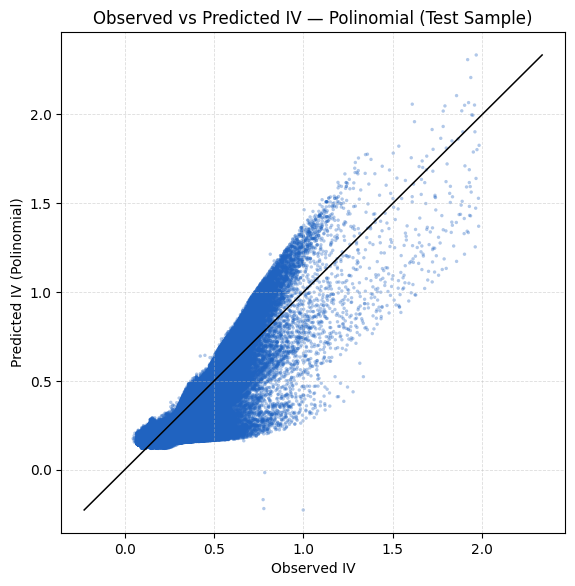

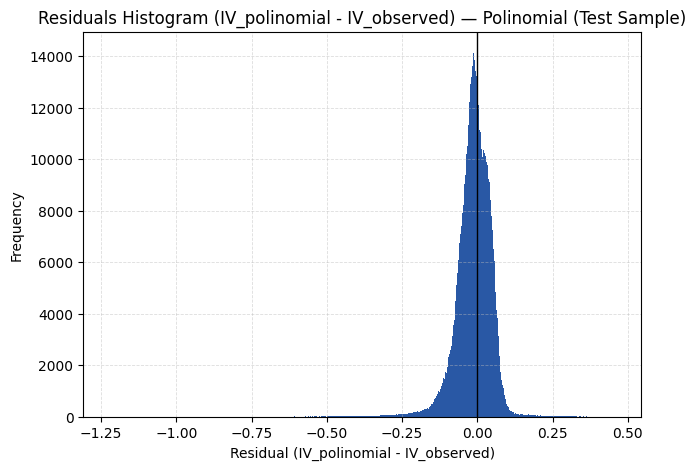

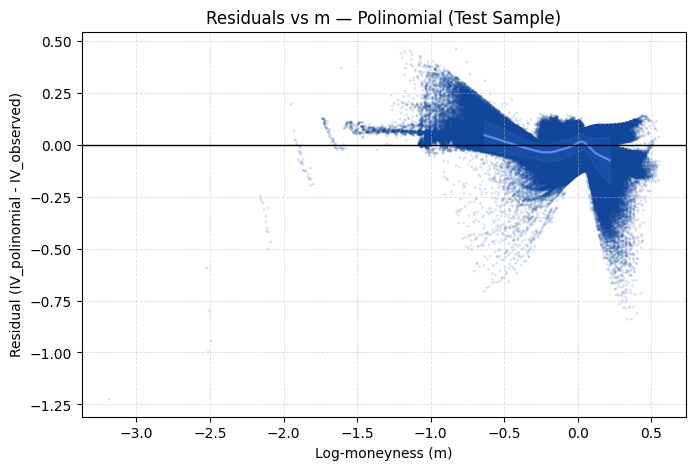

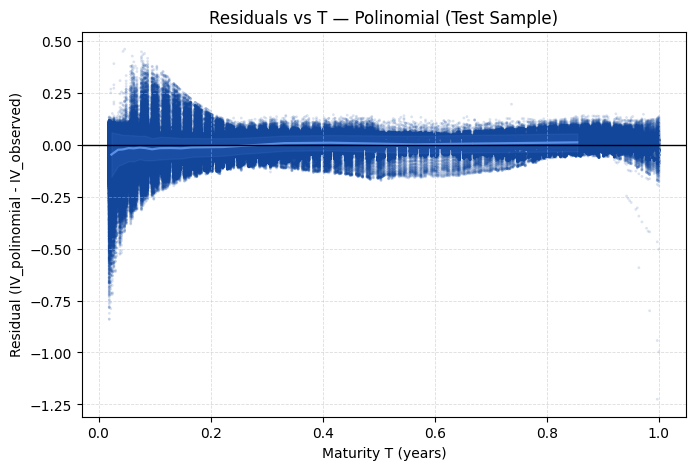

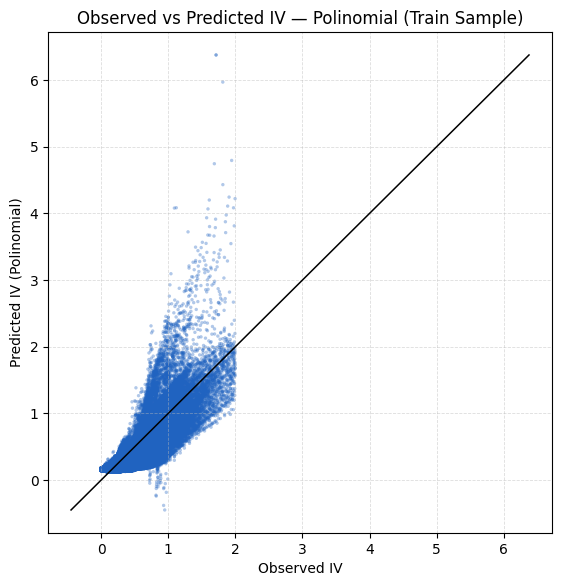

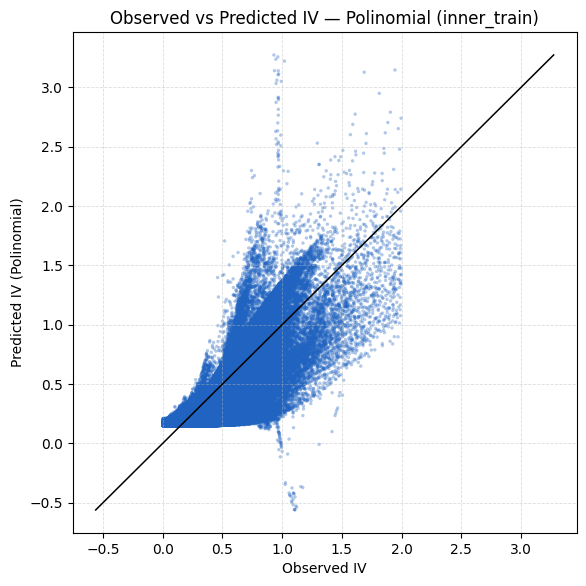

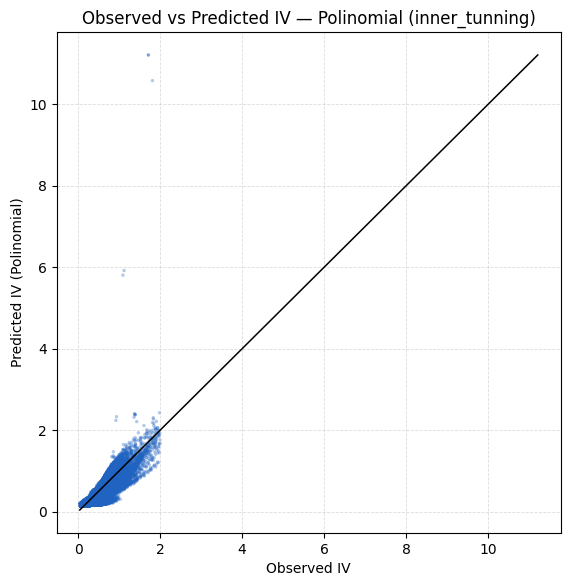

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Polinomial,test_puro,geral,train_full,1292514,0.059316,0.041980,0.032585,0.740785,-1.212789e-02
1,Polinomial,train_full,especifica,train_full,7505238,0.063155,0.044488,0.034345,0.744303,-1.023652e-12
2,Polinomial,Test Sample,geral,train_full,1292514,0.059393,0.042028,0.032607,0.740112,-1.219785e-02
3,Polinomial,Train Sample,especifica,train_full,7505238,0.063161,0.044483,0.034331,0.744249,-1.024191e-12
4,Polinomial,inner_train,especifica,inner_training,5970843,0.068442,0.048019,0.037002,0.698522,-7.139899e-13
5,Polinomial,inner_tunning,especifica,inner_training,1534395,0.058277,0.041917,0.034844,0.783745,7.974329e-03


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Polinomial,test_puro,geral,train_full,1292514,0.059316,0.041980,0.032585,0.740785,-1.212789e-02
1,Polinomial,train_full,especifica,train_full,7505238,0.063155,0.044488,0.034345,0.744303,-1.023652e-12
2,Polinomial,Test Sample,geral,train_full,1292514,0.059393,0.042028,0.032607,0.740112,-1.219785e-02
3,Polinomial,Train Sample,especifica,train_full,7505238,0.063161,0.044483,0.034331,0.744249,-1.024191e-12
4,Polinomial,inner_train,especifica,inner_training,5970843,0.068442,0.048019,0.037002,0.698522,-7.139899e-13


In [14]:
# --- Run model evaluation pipeline ---
res_poly = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém a coluna iv_poly_d*_...
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="Polinomial",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",          # "all" | "subsample" | "hexbin"
    max_points_scatter=250_000,  # só usado se scatter_mode="subsample"
    dpi=160,
    display_in_notebook=True     # mostra gráficos + tabela no output do VS Code
)

# Se precisares da tabela em variável:
res_poly["globais_df"].head()

### 11. 3D Volatility Surface & Residual Diagnostics


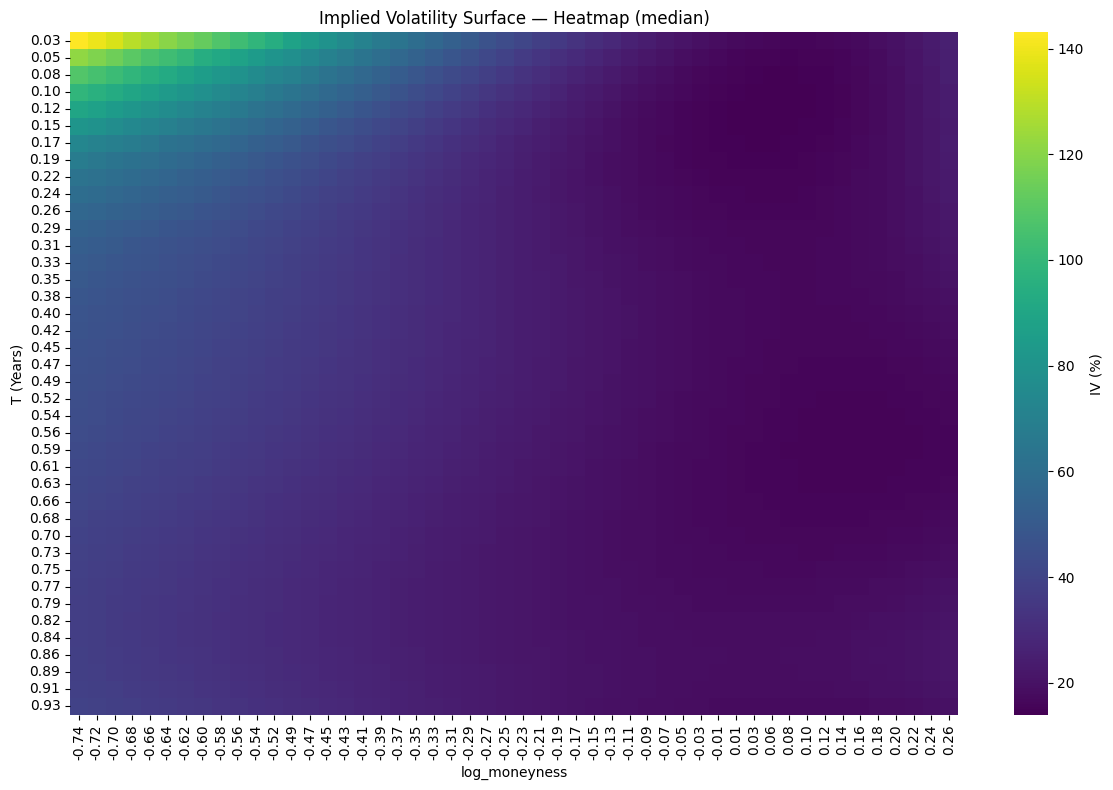

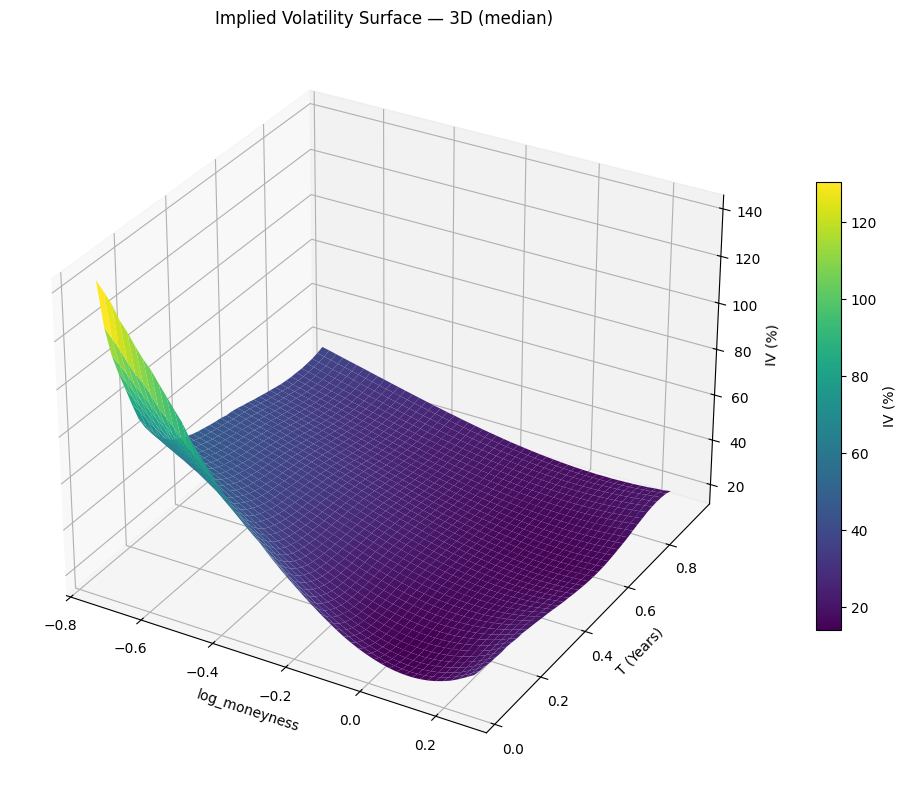

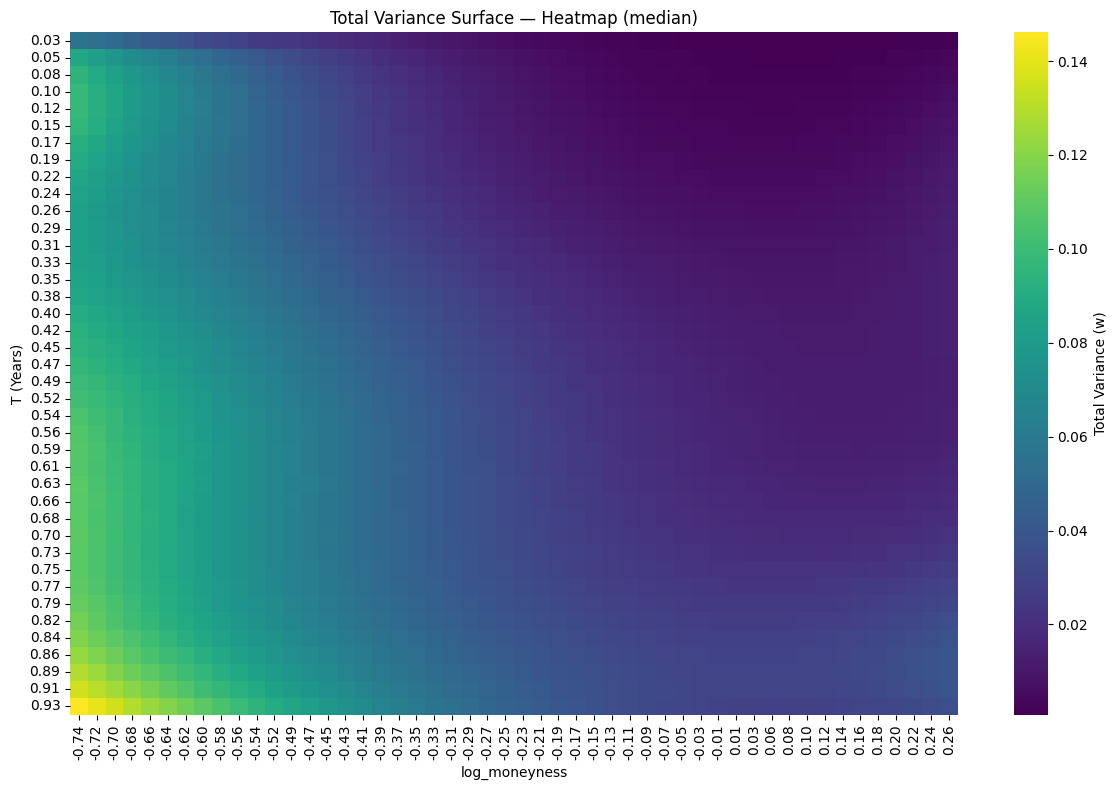

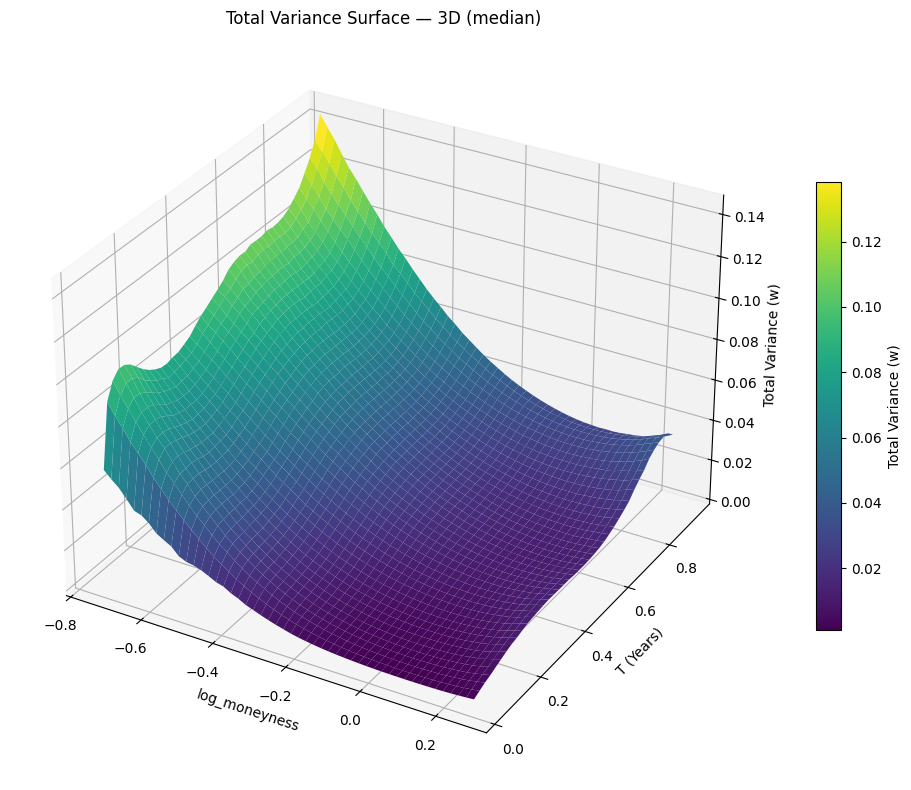

In [15]:
# 1) IVS e Superfícies de Variância do Modelo
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Polinomial"
)